In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm
from cartopy.util import add_cyclic_point


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_

In [3]:
#IMPORT DATASET
#!cdo selmon,12,1,2 ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc')
#!cdo selmon,12,1,2 ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_1940-2023.nc ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_djf_1940-2023.nc
ds_comp = xr.load_dataset('../IVT/ERA5_IVT_northem_daily_2.5x2.5_jja_1940-2023.nc')
#store variables for the composite
lon = ds['lon']
lat = ds['lat']
times = ds['time']
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
#DAV = add_cyclic_point(DAV,coord=lon)
#zg,lon = add_cyclic_point(zg,coord=lon)
anom = ds_comp['IVT'] - ds_comp['IVT'].mean('time') #converted to KJ


In [4]:
anom.shape

(7728, 37, 145)

In [5]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [6]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = DAV.loc[:,plat,plon]
list = []
list_an = []
#winter
#list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
#list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]#summer
#summer
list_east = [155, 260, 357, 429, 522, 648, 698, 707, 754, 795, 836, 903, 911, 950, 1076, 1173, 1220, 1226, 1267, 1271, 1353, 1412, 1456, 1508, 1555, 1563, 1637, 1639, 1720, 1723, 1729, 1800, 1802, 1848, 1854, 1896, 1903, 1997, 1998, 2100, 2105, 2107, 2142, 2229, 2230, 2241, 2280, 2326, 2361, 2365, 2377, 2413, 2424, 2459, 2510, 2543, 2593, 2625, 2634, 2684, 2719, 2727, 2758, 2764, 2773, 2813, 2898, 2968, 3007, 3047, 3052, 3135, 3142, 3146, 3189, 3269, 3271, 3312, 3317, 3321, 3376, 3377, 3417, 3457, 3460, 3466, 3536, 3539, 3542, 3625]
list_west = [44, 74, 302, 309, 353, 477, 517, 597, 660, 905, 1035, 1403, 1409, 1445, 1642, 1724, 1804, 1948, 1956, 2002, 2040, 2232, 2417, 2631, 2680, 2772, 2899, 2929, 3013, 3061, 3180, 3192, 3223, 3231, 3234, 3318, 3322, 3369, 3468, 3570, 3577, 3621]
for t,time in enumerate(times):
    if series[t] in list_west:#in list_west:
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp_west = sum_t/len(list)
anom_comp_west = sum_an/len(list_an)
t_st_anom_west = abs(anom_comp_west/Bootstrap(anom,len(list_an),1000)) > 2


In [7]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = DAV.loc[:,plat,plon]
list = []
list_an = []
#winter
#list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
#list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]
#summer
list_east = [155, 260, 357, 429, 522, 648, 698, 707, 754, 795, 836, 903, 911, 950, 1076, 1173, 1220, 1226, 1267, 1271, 1353, 1412, 1456, 1508, 1555, 1563, 1637, 1639, 1720, 1723, 1729, 1800, 1802, 1848, 1854, 1896, 1903, 1997, 1998, 2100, 2105, 2107, 2142, 2229, 2230, 2241, 2280, 2326, 2361, 2365, 2377, 2413, 2424, 2459, 2510, 2543, 2593, 2625, 2634, 2684, 2719, 2727, 2758, 2764, 2773, 2813, 2898, 2968, 3007, 3047, 3052, 3135, 3142, 3146, 3189, 3269, 3271, 3312, 3317, 3321, 3376, 3377, 3417, 3457, 3460, 3466, 3536, 3539, 3542, 3625]
list_west = [44, 74, 302, 309, 353, 477, 517, 597, 660, 905, 1035, 1403, 1409, 1445, 1642, 1724, 1804, 1948, 1956, 2002, 2040, 2232, 2417, 2631, 2680, 2772, 2899, 2929, 3013, 3061, 3180, 3192, 3223, 3231, 3234, 3318, 3322, 3369, 3468, 3570, 3577, 3621]
for t,time in enumerate(times):
    if series[t] in list_east:#in list_west:
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp_east = sum_t/len(list)
anom_comp_east = sum_an/len(list_an)
t_st_anom_east = abs(anom_comp_east/Bootstrap(anom,len(list_an),1000)) > 2


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.8/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


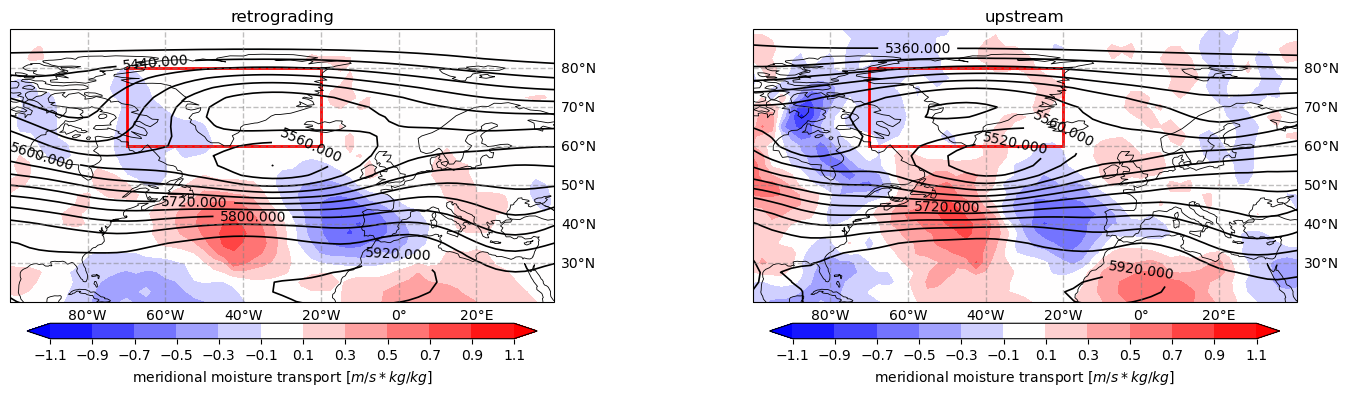

In [8]:
# Example data (you need to provide your own data for these variables)
# zg_comp, plon, plat, lon, lat, anom_comp should be defined in your script

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(15, 4), subplot_kw={'projection': ccrs.PlateCarree()})

lon = ds['lon']
lon_comp = ds_comp['longitude']

titles = ['retrograding','upstream']
fields = [zg_comp_east,zg_comp_west]
anom_comp = [anom_comp_east,anom_comp_west]
extent = [-100, 40, 20, 90]  # Greenland
# extent =[-180,180,20,90] # Europe

for i,ax in enumerate(axarr):  # Loop over both axes
    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines(linewidth=0.6)
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='--')

    if True:
        lat_min, lat_max = 60, 80
        lon_min, lon_max = -70, -20
        # Plot the rectangle
        rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                             edgecolor='red', facecolor='none', linewidth=2,
                             transform=ccrs.PlateCarree())
        ax.add_patch(rect)

    gl.xlabels_top = False
    gl.ylabels_left = False

    cont = ax.contour(lon, lat, fields[i],
                      colors='black',
                      alpha=1.,
                      linewidths=1.2,
                      levels=np.arange(4600, 7200, 40))
    
    #c_range = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/8)) + np.array(np.amax(abs(anom_comp_west))/16)
    c_range = np.arange(-1.1, 1.2, 0.2)
    #ticks = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/4)) + np.array(np.amax(abs(anom_comp_west))/8)
    ticks = np.arange(-1.1, 1.2, 0.2)

    plt.clabel(cont, inline=True, fontsize=10)

    shadings = ax.contourf(lon_comp, lat, anom_comp[i],
                           cmap='bwr',
                           extend='both',
                           levels=c_range)
    fig.colorbar(shadings,label='meridional moisture transport [$m/s * kg/kg$]',orientation = "horizontal" ,ticks = ticks,fraction=0.05,pad = 0.07 ,aspect = 30,ax=ax)

for i,ax in enumerate(axarr):
    ax.set_title(titles[i])

plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/greenland_article/summer_composite_greenland_IVT_west_multiplot.png', dpi=300)
